# Digital Use Conditions, Indigenous Data Sovereignty & OAMI Analysis
### PMC FAIR Study 2011–2025

This notebook examines three interconnected dimensions of open-science governance
that sit *alongside* but frequently in tension with the FAIR principles:

---

## 1 · Digital Use Conditions (DUC)

**What it is:** The license, copyright statement, and access conditions under which
shared data may be reused. FAIR's *Reusable* principle (R1.1) explicitly requires
that data be released with a clear and accessible data usage license — yet most DAS
analysis focuses on *whether* data is shared, not *under what terms*.

Key license categories tracked here:
| Category | Examples | FAIR-R1.1 compliant? |
|----------|---------|---------------------|
| **Open (CC0 / Public Domain)** | CC0, PD, public domain | ✅ Fully |
| **Open with attribution (CC-BY)** | CC-BY 4.0, CC-BY-SA | ✅ Yes |
| **Non-commercial restriction** | CC-BY-NC, CC-BY-NC-SA | ⚠️ Partially |
| **No-derivatives restriction** | CC-BY-ND | ⚠️ Partially |
| **All rights reserved** | © publisher, "data not for redistribution" | ❌ Non-reusable |
| **Proprietary / unclear** | No license stated, "contact authors" | ❌ Unknown |

---

## 2 · Indigenous Data Sovereignty & the CARE Principles

**What it is:** The CARE principles (Collective Benefit, Authority to Control,
Responsibility, Ethics) are indigenous-data governance principles developed by the
Global Indigenous Data Alliance (2019) as a complement and corrective to FAIR.
Where FAIR focuses on technical openness, CARE asserts that not all data *should*
be freely open — particularly data about indigenous peoples, communities, and lands.

Signals we look for in DAS text and article keywords:
- Explicit references to indigenous, tribal, or First Nations data
- References to community consent, data governance, or data sovereignty
- References to CARE principles, GIDA, or indigenous data repositories
- Restricted data with community-justification language

---

## 3 · OAMI — Open Access Media Importer (Wikimedia Commons)

**What it is:** The [Open Access Media Importer Bot](https://commons.wikimedia.org/wiki/User:Open_Access_Media_Importer_Bot)
automatically imports audio and video supplementary files from open-access PMC
articles into Wikimedia Commons, making them freely reusable under open licenses.

This represents a concrete FAIRification pathway: multimedia files moving from
journal supplementary material (minimal metadata, publisher-locked) to a globally
accessible repository (persistent URI, rich metadata, open license, machine-readable).

We analyse:
- How many PMC articles in our corpus have audio/video supplementary files
- What MIME types are present (audio/\*, video/\*, application/\*)
- License compatibility for OAMI import (requires CC0 or CC-BY)
- Trend over time: is multimedia supplementary sharing growing?
- data-sharing score of articles with multimedia vs text-only supplementary files

---

## Section map
| § | Topic |
|---|-------|
| 0 | Setup & data loading |
| 1 | License landscape — what terms govern shared data? |
| 2 | License type × data-sharing score — does license openness predict higher data-sharing score? |
| 3 | License trend over time — is open licensing growing? |
| 4 | DUC completeness — do DAS statements specify reuse conditions? |
| 5 | Indigenous data signals — CARE principle proxies in DAS text |
| 6 | OAMI eligibility — audio/video supplementary files |
| 7 | Multimedia MIME type breakdown |
| 8 | OAMI × license compatibility — which articles could be imported? |
| 9 | FAIRification pathway: supplement → repository |
| 10 | DUC × funder — do open funders mandate open licenses? |
| 11 | Statistical summary + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## §0 — Setup & Data Loading

In [2]:
import sqlite3, re, warnings
import matplotlib; import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.15)
FIG_W, FIG_H = 14, 5

FAIR_YEAR    = 2016
MANDATE_YEAR = 2019

C_OPEN   = '#2ca02c'   # open license
C_ATTR   = '#59a14f'   # attribution
C_NC     = '#ff7f0e'   # non-commercial restriction
C_AR     = '#d62728'   # all rights reserved
C_UNK    = '#bab0ac'   # unknown/unclear
C_INDIG  = '#9467bd'   # indigenous
C_MEDIA  = '#17becf'   # multimedia
C_PRE    = '#4e79a7'
C_POST   = '#e15759'

# ── License classification regexes ────────────────────────────────────────
LIC_PATTERNS = [
    ('cc0_pd',   re.compile(
        r'cc[\s\-]?0|creative\s+commons\s+zero|public\s+domain'
        r'|cc0\s+1\.0|pdm|no\s+rights\s+reserved', re.I),
        'CC0 / Public Domain', C_OPEN),
    ('cc_by',    re.compile(
        r'cc[\s\-]by[\s\-](?:sa[\s\-])?(?:4|3|2)(?:\.0)?(?!\s*nc)(?!\s*nd)'
        r'|creative\s+commons\s+attribution(?:\s+share.?alike)?(?!\s*non)',
        re.I),
        'CC-BY / CC-BY-SA', C_ATTR),
    ('cc_by_nc', re.compile(
        r'cc[\s\-]by[\s\-]nc|creative\s+commons.*?non.?commercial', re.I),
        'CC-BY-NC (restricted)', C_NC),
    ('cc_by_nd', re.compile(
        r'cc[\s\-]by[\s\-]nd|no.?deriv', re.I),
        'CC-BY-ND (no derivatives)', C_NC),
    ('arr',      re.compile(
        r'all\s+rights\s+reserved|copyright.*?(?:journal|publisher|society)'
        r'|not\s+for\s+redistribution|proprietary', re.I),
        'All rights reserved', C_AR),
    ('ogl',      re.compile(
        r'open\s+government\s+licen[cs]e|OGL', re.I),
        'Open Government License', C_ATTR),
    ('mit_apache', re.compile(
        r'\bMIT\s+licen[cs]e|\bApache\s+(?:2\.0\s+)?licen[cs]e|GPL\b', re.I),
        'MIT/Apache/GPL (software)', C_ATTR),
]

def classify_license(lic_str, copyright_str=''):
    combined = str(lic_str or '') + ' ' + str(copyright_str or '')
    for key, pat, label, clr in LIC_PATTERNS:
        if pat.search(combined):
            return key, label, clr
    if combined.strip() in ('', ' '):
        return 'no_info', 'No license info', C_UNK
    return 'unclear', 'Unclear / proprietary', C_AR

# ── Indigenous data signals ────────────────────────────────────────────────
INDIGENOUS_RE = re.compile(
    r'indigenous|aboriginal|first\s+nation|tribal|native\s+(?:american|people|community)'
    r'|maori|inuit|indig[ei]nous\s+data|data\s+sovereign|CARE\s+principle'
    r'|community.?consent|traditional\s+knowledge|traditional\s+owner'
    r'|GIDA|indigenous\s+data\s+governance|local\s+community\s+(?:data|consent)'
    r'|biocultural|traditional\s+ecological\s+knowledge', re.I)

CARE_SPECIFIC_RE = re.compile(
    r'CARE\s+principle|collective\s+benefit|authority\s+to\s+control'
    r'|data\s+sovereignty|indigenous\s+data\s+alliance'
    r'|Global\s+Indigenous\s+Data\s+Alliance', re.I)

# ── OAMI / multimedia MIME patterns ───────────────────────────────────────
AUDIO_RE = re.compile(r'^audio/', re.I)
VIDEO_RE = re.compile(r'^video/', re.I)
# OAMI-importable: must be CC0 or CC-BY (not NC, not ND, not AR)
OAMI_OPEN_LIC = {'cc0_pd', 'cc_by', 'ogl', 'mit_apache'}

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}

HAS_SUPP   = 'supplementary_material' in tables
HAS_FUNDER = 'article_funder'         in tables
HAS_DISC   = 'article_discipline'     in tables
HAS_ETHICS = 'ethics_statement'       in tables

for lbl, flag in [
        ('supplementary_material', HAS_SUPP),
        ('article_funder (Stg6)', HAS_FUNDER),
        ('article_discipline   ', HAS_DISC)]:
    print(f'  {"OK" if flag else "--"}  {lbl}')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


  OK  supplementary_material
  OK  article_funder (Stg6)
  OK  article_discipline   


### Master frame — articles with license + DAS info

In [3]:
df = qdb("""
    SELECT
        a.article_id,
        a.year      AS year,
        a.journal_id,
        COALESCE(a.license, '')      AS license_raw,
        COALESCE(a.copyright_statement, '') AS copyright_raw,
        COALESCE(a.keywords, '')     AS keywords,
        COALESCE(a.title, '')        AS title,
        dc.data_sharing_score,
        dc.primary_category          AS das_cat,
        dc.mentions_license,
        COALESCE(da.statement, '')   AS das_text,
        COALESCE(da.source, '')      AS das_source
    FROM article a
    JOIN das_category dc     ON dc.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

# Classify licenses
lic_classified = df.apply(
    lambda r: classify_license(r['license_raw'], r['copyright_raw']), axis=1)
df['lic_key']   = lic_classified.apply(lambda x: x[0])
df['lic_label'] = lic_classified.apply(lambda x: x[1])
df['lic_clr']   = lic_classified.apply(lambda x: x[2])

# Open license flag (CC0 or CC-BY — OAMI-eligible)
df['lic_open']   = df['lic_key'].isin({'cc0_pd', 'cc_by', 'ogl', 'mit_apache'})
df['lic_cc0']    = df['lic_key'] == 'cc0_pd'
df['lic_ccby']   = df['lic_key'] == 'cc_by'
df['lic_ncnd']   = df['lic_key'].isin({'cc_by_nc', 'cc_by_nd'})
df['lic_arr']    = df['lic_key'] == 'arr'
df['lic_known']  = df['lic_key'] != 'no_info'

# Indigenous / CARE signals
combined_text = df['das_text'] + ' ' + df['keywords'] + ' ' + df['title']
df['has_indigenous'] = combined_text.apply(
    lambda t: bool(INDIGENOUS_RE.search(str(t))))
df['has_care_explicit'] = combined_text.apply(
    lambda t: bool(CARE_SPECIFIC_RE.search(str(t))))

# DAS mentions license explicitly
df['das_mentions_lic'] = df['das_text'].apply(
    lambda t: bool(re.search(
        r'cc[\s\-]?(?:0|by|sa)|creative\s+commons|open\s+licen[cs]|'
        r'public\s+domain|available\s+under', str(t), re.I)))

n = len(df)
print(f'Master frame: {n:,} articles')
print(f'  License info present : {df["lic_known"].sum():>8,}  ({df["lic_known"].mean()*100:.1f}%)')
print(f'  Open license         : {df["lic_open"].sum():>8,}  ({df["lic_open"].mean()*100:.1f}%)')
print(f'  CC0/Public domain    : {df["lic_cc0"].sum():>8,}  ({df["lic_cc0"].mean()*100:.1f}%)')
print(f'  CC-BY / CC-BY-SA     : {df["lic_ccby"].sum():>8,}  ({df["lic_ccby"].mean()*100:.1f}%)')
print(f'  NC or ND restriction : {df["lic_ncnd"].sum():>8,}  ({df["lic_ncnd"].mean()*100:.1f}%)')
print(f'  All rights reserved  : {df["lic_arr"].sum():>8,}  ({df["lic_arr"].mean()*100:.1f}%)')
print(f'  Indigenous signals   : {df["has_indigenous"].sum():>8,}  ({df["has_indigenous"].mean()*100:.3f}%)')
print(f'  CARE explicit refs   : {df["has_care_explicit"].sum():>8,}')


Master frame: 6,874,176 articles
  License info present : 6,871,444  (100.0%)
  Open license         : 3,916,999  (57.0%)
  CC0/Public domain    :  446,388  (6.5%)
  CC-BY / CC-BY-SA     : 3,469,339  (50.5%)
  NC or ND restriction :  489,007  (7.1%)
  All rights reserved  :  286,256  (4.2%)
  Indigenous signals   :   15,553  (0.226%)
  CARE explicit refs   :      258


---
## §1 — License Landscape: What Terms Govern Shared Data?

FAIR's R1.1 requires data to be released under a clear, accessible usage license.
We examine what proportion of the corpus has explicit license information,
the distribution of license types, and where license data comes from
(article metadata vs DAS text vs neither).

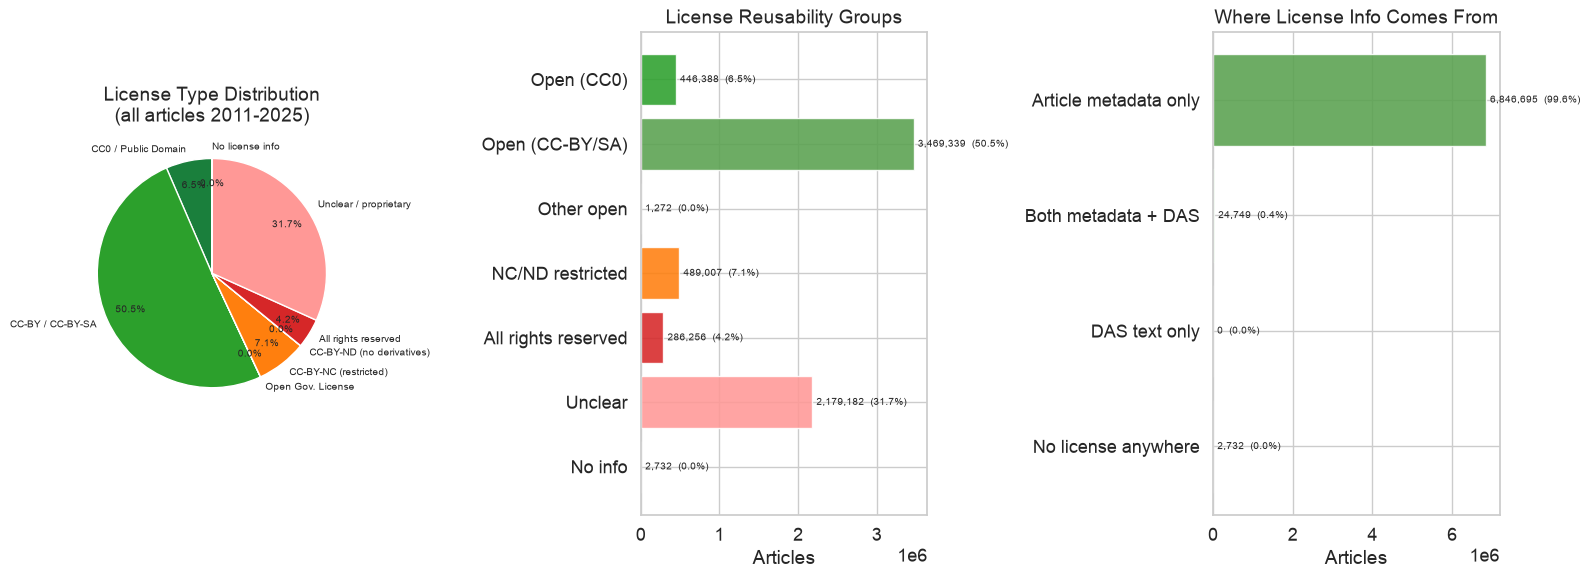

Open license rate (FAIR R1.1 compliant): 57.0%
No license information at all          : 0.0%


In [4]:
LIC_ORDER  = ['cc0_pd','cc_by','ogl','mit_apache','cc_by_nc','cc_by_nd','arr','unclear','no_info']
LIC_LABELS = {k: v for _, _, v, _ in [
    ('cc0_pd',    None,'CC0 / Public Domain',        None),
    ('cc_by',     None,'CC-BY / CC-BY-SA',           None),
    ('ogl',       None,'Open Gov. License',          None),
    ('mit_apache',None,'MIT/Apache/GPL',             None),
    ('cc_by_nc',  None,'CC-BY-NC (restricted)',      None),
    ('cc_by_nd',  None,'CC-BY-ND (no derivatives)',  None),
    ('arr',       None,'All rights reserved',        None),
    ('unclear',   None,'Unclear / proprietary',      None),
    ('no_info',   None,'No license info',            None),
] for k, _, v, _ in [
    ('cc0_pd',    None,'CC0 / Public Domain',        None),
    ('cc_by',     None,'CC-BY / CC-BY-SA',           None),
    ('ogl',       None,'Open Gov. License',          None),
    ('mit_apache',None,'MIT/Apache/GPL',             None),
    ('cc_by_nc',  None,'CC-BY-NC (restricted)',      None),
    ('cc_by_nd',  None,'CC-BY-ND (no derivatives)',  None),
    ('arr',       None,'All rights reserved',        None),
    ('unclear',   None,'Unclear / proprietary',      None),
    ('no_info',   None,'No license info',            None),
]}
LIC_CLRS_MAP = {
    'cc0_pd': '#1a7f3c', 'cc_by': '#2ca02c', 'ogl': '#5eba7d',
    'mit_apache': '#a8e6a3', 'cc_by_nc': '#ff7f0e', 'cc_by_nd': '#ffbb78',
    'arr': '#d62728', 'unclear': '#ff9896', 'no_info': '#bab0ac',
}

lic_vc = df['lic_key'].value_counts().reindex(LIC_ORDER).dropna()

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) Pie
ax = axes[0]
clrs_p = [LIC_CLRS_MAP[k] for k in lic_vc.index]
_, txts, pcts = ax.pie(lic_vc.values,
    labels=[LIC_LABELS.get(k, k) for k in lic_vc.index],
    colors=clrs_p, autopct='%1.1f%%', startangle=90, pctdistance=0.78)
for t in txts: t.set_fontsize(7)
for t in pcts: t.set_fontsize(7)
ax.set_title('License Type Distribution\n(all articles 2011-2025)')

# (b) Bar: open vs restricted vs unknown
ax = axes[1]
groups = {
    'Open (CC0)':          df['lic_cc0'].sum(),
    'Open (CC-BY/SA)':     df['lic_ccby'].sum(),
    'Other open':          df['lic_key'].isin({'ogl','mit_apache'}).sum(),
    'NC/ND restricted':    df['lic_ncnd'].sum(),
    'All rights reserved': df['lic_arr'].sum(),
    'Unclear':             (df['lic_key'] == 'unclear').sum(),
    'No info':             (df['lic_key'] == 'no_info').sum(),
}
gclrs = [C_OPEN, C_ATTR, '#5eba7d', C_NC, C_AR, '#ff9896', C_UNK]
bars = ax.barh(list(groups)[::-1], list(groups.values())[::-1],
               color=gclrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{v:,}  ({v/n*100:.1f}%)'
             for v in list(groups.values())[::-1]], padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('License Reusability Groups')

# (c) License source: metadata vs DAS text
ax = axes[2]
sources = {
    'Article metadata only':  ((df['lic_known']) & (~df['das_mentions_lic'])).sum(),
    'Both metadata + DAS':    ((df['lic_known']) & (df['das_mentions_lic'])).sum(),
    'DAS text only':          ((~df['lic_known']) & (df['das_mentions_lic'])).sum(),
    'No license anywhere':    ((~df['lic_known']) & (~df['das_mentions_lic'])).sum(),
}
sclrs = [C_ATTR, C_OPEN, C_NC, C_UNK]
bars2 = ax.barh(list(sources)[::-1], list(sources.values())[::-1],
                color=sclrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, labels=[f'{v:,}  ({v/n*100:.1f}%)'
             for v in list(sources.values())[::-1]], padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('Where License Info Comes From')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_01_landscape.png", **SAVEFIG_KWARGS)
plt.show()
pct_open = df['lic_open'].mean()*100
print(f'Open license rate (FAIR R1.1 compliant): {pct_open:.1f}%')
print(f'No license information at all          : {(df["lic_key"]=="no_info").mean()*100:.1f}%')


---
## §2 — License Type × Data-Sharing Score

Does license openness predict higher data-sharing scores? We expect a positive
correlation: authors who choose open licenses also tend to use named
repositories and provide accession numbers (all practices associated with a higher data-sharing score).

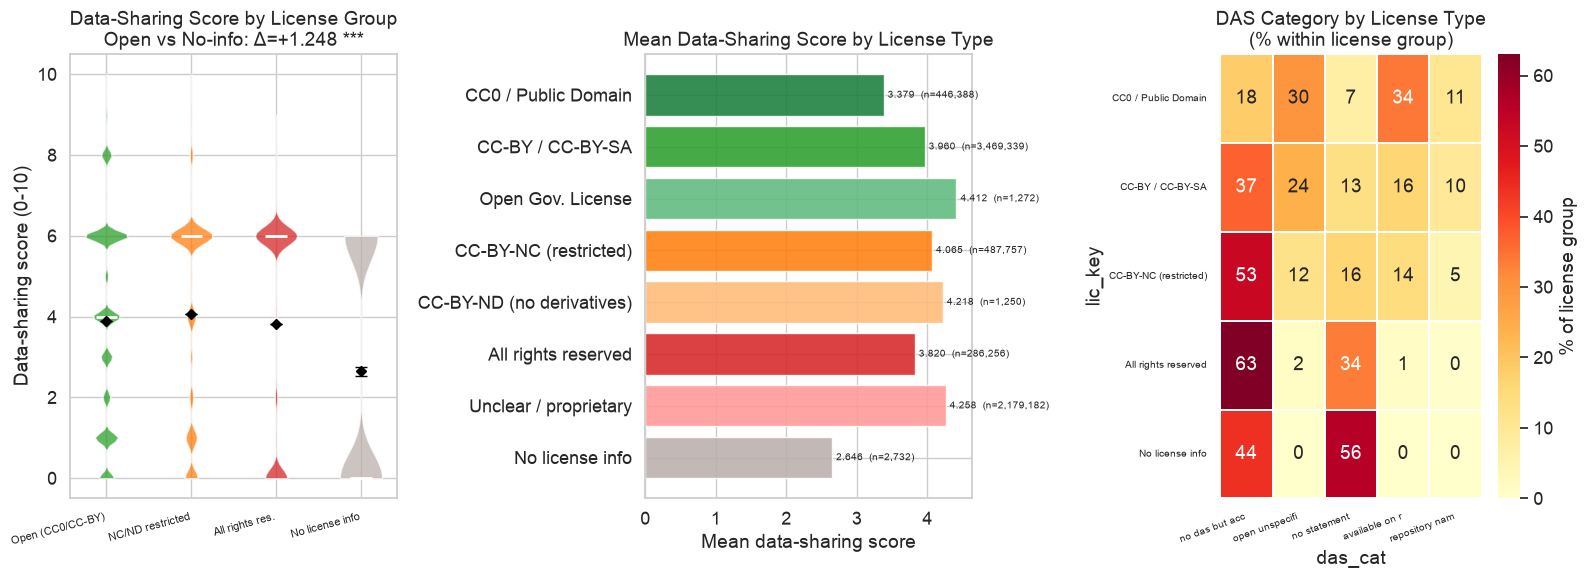

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) Violin: data-sharing score by license reusability group
groups_v = [
    ('Open (CC0/CC-BY)', df[df['lic_open']]['data_sharing_score'].dropna(), C_OPEN),
    ('NC/ND restricted', df[df['lic_ncnd']]['data_sharing_score'].dropna(), C_NC),
    ('All rights res.',  df[df['lic_arr']]['data_sharing_score'].dropna(), C_AR),
    ('No license info',  df[df['lic_key']=='no_info']['data_sharing_score'].dropna(), C_UNK),
]
valid_v = [(lbl, d, c) for lbl, d, c in groups_v if len(d) >= 2]
ax = axes[0]
parts = ax.violinplot([d for _, d, _ in valid_v], showmedians=True, showextrema=False)
for pc, (_, _, c) in zip(parts['bodies'], valid_v):
    pc.set_facecolor(c); pc.set_alpha(0.75)
parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
for i, (_, d, _) in enumerate(valid_v):
    ax.errorbar(i+1, d.mean(), yerr=1.96*d.std()/len(d)**0.5,
                fmt='D', color='black', ms=5, capsize=4, zorder=5)
ax.set_xticks(range(1, len(valid_v)+1))
ax.set_xticklabels([l for l, _, _ in valid_v], rotation=15, ha='right', fontsize=8)
ax.set_ylabel('Data-sharing score (0-10)')
ax.set_title('Data-Sharing Score by License Group\n(violin + 95% CI)')

# Mann-Whitney: open vs no-info
sc_open   = df[df['lic_open']]['data_sharing_score'].dropna()
sc_no_lic = df[df['lic_key']=='no_info']['data_sharing_score'].dropna()
if len(sc_open)>=2 and len(sc_no_lic)>=2:
    u, p = stats.mannwhitneyu(sc_open, sc_no_lic, alternative='two-sided')
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    axes[0].set_title(f'Data-Sharing Score by License Group\n'
                      f'Open vs No-info: Δ={sc_open.mean()-sc_no_lic.mean():+.3f} {sig}')

# (b) Mean data-sharing score per license key
ax = axes[1]
lic_fair = (df.groupby('lic_key').agg(
    n=('article_id','count'), mean_fair=('data_sharing_score','mean')
).reindex(LIC_ORDER).dropna().reset_index())
lic_fair['label'] = lic_fair['lic_key'].map(LIC_LABELS)
bar_clrs = [LIC_CLRS_MAP[k] for k in lic_fair['lic_key']]
bars = ax.barh(lic_fair['label'][::-1], lic_fair['mean_fair'][::-1],
               color=bar_clrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{m:.3f}  (n={int(n):,})'
             for m, n in zip(lic_fair['mean_fair'][::-1], lic_fair['n'][::-1])],
             padding=3, fontsize=7.5)
ax.set_xlabel('Mean data-sharing score')
ax.set_title('Mean Data-Sharing Score by License Type')

# (c) License × das_cat heatmap (top categories)
ax = axes[2]
lc_cross = pd.crosstab(df['lic_key'], df['das_cat'])
top_cats = df['das_cat'].value_counts().head(5).index.tolist()
top_lics = ['cc0_pd','cc_by','cc_by_nc','arr','no_info']
lc_sub = lc_cross.loc[
    [k for k in top_lics if k in lc_cross.index],
    [c for c in top_cats if c in lc_cross.columns]
]
lc_pct = lc_sub.div(lc_sub.sum(axis=1), axis=0) * 100
sns.heatmap(lc_pct, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.3, cbar_kws={'label': '% of license group'})
ax.set_yticklabels([LIC_LABELS.get(k,k) for k in lc_pct.index],
                   rotation=0, fontsize=7.5)
ax.set_xticklabels([c.replace('_',' ')[:14] for c in lc_pct.columns],
                   rotation=20, ha='right', fontsize=7.5)
ax.set_title('DAS Category by License Type\n(% within license group)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_02_fair_license.png", **SAVEFIG_KWARGS)
plt.show()


---
## §3 — License Openness Trend Over Time

Is the open-licensing movement gaining ground in biomedical publishing?
We track the share of CC0 and CC-BY articles over 15 years, marking
the 2016 FAIR paper and key OA mandate milestones.

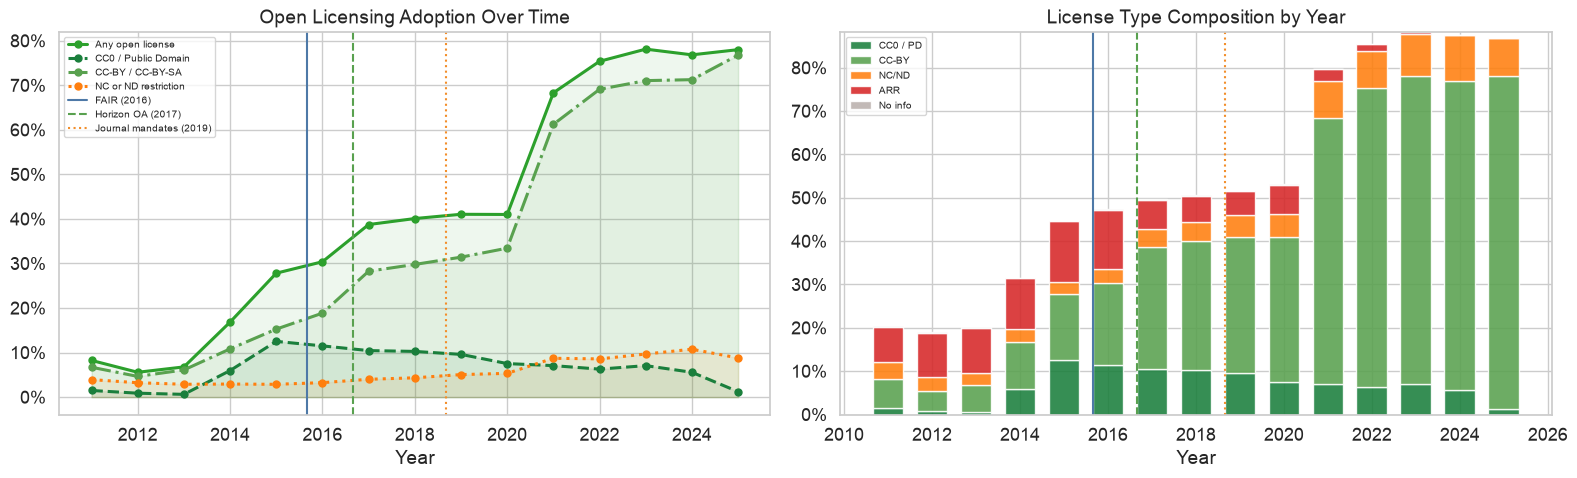

 year  pct_open  pct_cc0  pct_ccby  pct_ncnd  pct_arr  pct_no_lic
 2011      8.24     1.49      6.71      3.93     8.17        0.23
 2012      5.58     0.88      4.65      3.23    10.12        0.21
 2013      6.78     0.62      6.10      2.88    10.33        0.17
 2014     16.84     5.96     10.83      2.93    11.73        0.07
 2015     27.83    12.51     15.27      2.88    14.06        0.05
 2016     30.39    11.50     18.85      3.25    13.61        0.10
 2017     38.74    10.45     28.26      4.00     6.86        0.08
 2018     40.09    10.26     29.79      4.34     6.12        0.06
 2019     41.05     9.59     31.42      5.06     5.44        0.02
 2020     41.00     7.53     33.44      5.33     6.68        0.11
 2021     68.31     7.07     61.23      8.72     2.74        0.01
 2022     75.39     6.28     69.11      8.58     1.58        0.00
 2023     78.12     7.07     71.05      9.67     0.53        0.00
 2024     76.84     5.57     71.27     10.75     0.02        0.00
 2025     

In [6]:
yr_lic = df.groupby('year').agg(
    n_total      = ('article_id','count'),
    pct_open     = ('lic_open',  lambda x: x.mean()*100),
    pct_cc0      = ('lic_cc0',   lambda x: x.mean()*100),
    pct_ccby     = ('lic_ccby',  lambda x: x.mean()*100),
    pct_ncnd     = ('lic_ncnd',  lambda x: x.mean()*100),
    pct_arr      = ('lic_arr',   lambda x: x.mean()*100),
    pct_no_lic   = ('lic_key',   lambda x: (x=='no_info').mean()*100),
    pct_das_lic  = ('das_mentions_lic', lambda x: x.mean()*100),
).reset_index()
yr_lic = yr_lic[yr_lic['year'].between(2011, 2025)]

MLINES = [
    (2016 - 0.33, '#4e79a7', '-',  'FAIR (2016)'),
    (2017 - 0.33, '#59a14f', '--', 'Horizon OA (2017)'),
    (2019 - 0.33, '#f28e2b', ':',  'Journal mandates (2019)'),
]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
for col, clr, lbl, ls in [
        ('pct_open',   C_OPEN,  'Any open license',    '-'),
        ('pct_cc0',    '#1a7f3c','CC0 / Public Domain', '--'),
        ('pct_ccby',   C_ATTR,  'CC-BY / CC-BY-SA',    '-.'),
        ('pct_ncnd',   C_NC,    'NC or ND restriction', ':'),
]:
    ax.fill_between(yr_lic['year'], yr_lic[col], alpha=0.08, color=clr)
    ax.plot(yr_lic['year'], yr_lic[col], lw=2.2, marker='o', ms=5,
            color=clr, ls=ls, label=lbl)
for x, c, ls, lbl in MLINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Open Licensing Adoption Over Time')
ax.set_xlabel('Year'); ax.legend(fontsize=7)

ax = axes[1]
# Stacked 100% bar: license composition per year
yr_stk = yr_lic[['year','pct_cc0','pct_ccby','pct_ncnd','pct_arr','pct_no_lic']].copy()
# Renormalise (they won't sum to 100 if some are unclear)
for col in ['pct_cc0','pct_ccby','pct_ncnd','pct_arr','pct_no_lic']:
    pass  # already % of total, plot stacked
bot = np.zeros(len(yr_stk))
for col, clr, lbl in [
        ('pct_cc0',  '#1a7f3c','CC0 / PD'),
        ('pct_ccby', C_ATTR,  'CC-BY'),
        ('pct_ncnd', C_NC,    'NC/ND'),
        ('pct_arr',  C_AR,    'ARR'),
        ('pct_no_lic',C_UNK,  'No info'),
]:
    ax.bar(yr_stk['year'], yr_stk[col], bottom=bot,
           color=clr, alpha=0.88, label=lbl, edgecolor='white', width=0.7)
    bot = bot + yr_stk[col].values
for x, c, ls, _ in MLINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('License Type Composition by Year')
ax.set_xlabel('Year'); ax.legend(fontsize=7.5, loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_03_lic_trend.png", **SAVEFIG_KWARGS)
plt.show()
print(yr_lic[['year','pct_open','pct_cc0','pct_ccby','pct_ncnd','pct_arr','pct_no_lic']]
      .round(2).to_string(index=False))


---
## §4 — DUC Completeness: Does the DAS Specify Reuse Conditions?

A FAIR R1.1-compliant DAS should explicitly state the license under which
data can be reused. We score each article 0-3 on DUC completeness:
- **+1** license info in article metadata (JATS `<license>` element)
- **+1** license mentioned in DAS text
- **+1** open license (CC0 or CC-BY) rather than restricted/unknown

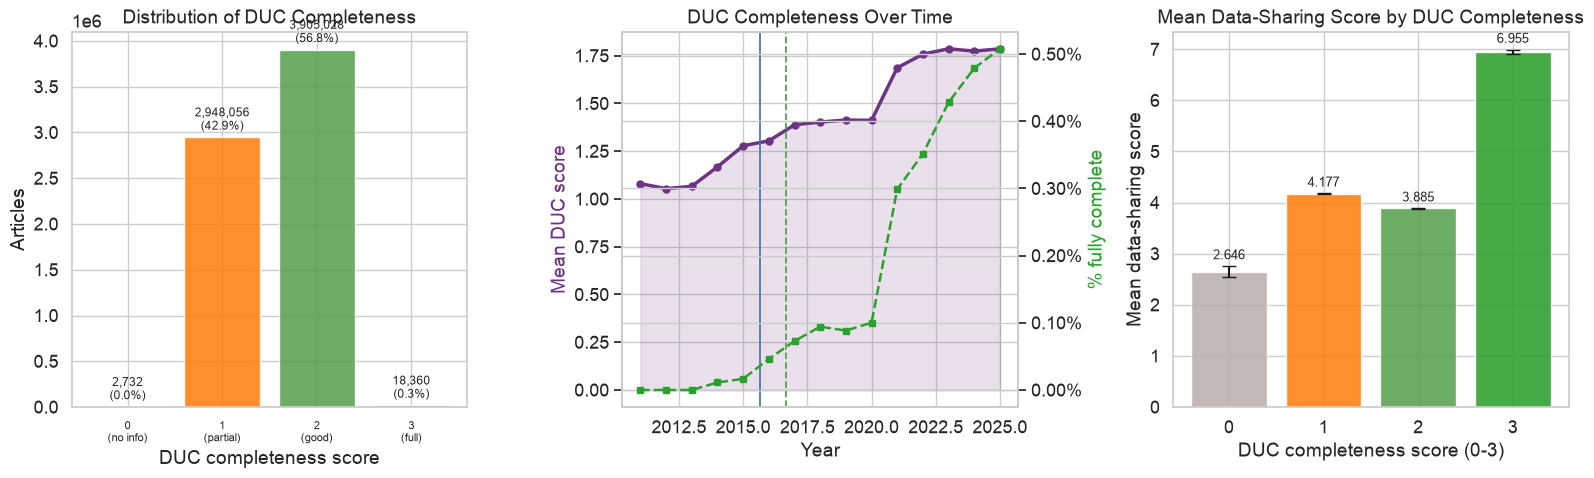

In [7]:
df['duc_score'] = (
    df['lic_known'].astype(int) +
    df['das_mentions_lic'].astype(int) +
    df['lic_open'].astype(int)
)

duc_yr = df.groupby('year').agg(
    mean_duc   = ('duc_score', 'mean'),
    pct_full   = ('duc_score', lambda x: (x==3).mean()*100),
    pct_zero   = ('duc_score', lambda x: (x==0).mean()*100),
).reset_index()
duc_yr = duc_yr[duc_yr['year'].between(2011, 2025)]

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
dist = df['duc_score'].value_counts().sort_index()
bar_c = [C_UNK, C_NC, C_ATTR, C_OPEN]
bars = ax.bar(dist.index, dist.values, color=bar_c[:len(dist)],
              alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{int(v):,}\n({v/len(df)*100:.1f}%)'
             for v in dist.values], padding=3, fontsize=8.5)
ax.set_xticks([0,1,2,3])
ax.set_xticklabels(['0\n(no info)', '1\n(partial)', '2\n(good)', '3\n(full)'], fontsize=8)
ax.set_xlabel('DUC completeness score')
ax.set_ylabel('Articles')
ax.set_title('Distribution of DUC Completeness')

ax = axes[1]
ax.fill_between(duc_yr['year'], duc_yr['mean_duc'], alpha=0.15, color='#6c3483')
ax.plot(duc_yr['year'], duc_yr['mean_duc'], lw=2.5, marker='o', ms=5,
        color='#6c3483', label='Mean DUC (0-3)')
ax2r = ax.twinx()
ax2r.plot(duc_yr['year'], duc_yr['pct_full'], lw=1.8, marker='s', ms=4,
          color=C_OPEN, ls='--', label='% fully complete (3/3)')
for x, c, ls, _ in MLINES[:2]:
    ax.axvline(x, color=c, lw=1.3, ls=ls)
ax.set_ylabel('Mean DUC score', color='#6c3483')
ax2r.set_ylabel('% fully complete', color=C_OPEN)
ax2r.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DUC Completeness Over Time')
ax.set_xlabel('Year')

ax = axes[2]
duc_fair = df.groupby('duc_score')['data_sharing_score'].agg(['mean','std','count']).reset_index()
bars2 = ax.bar(duc_fair['duc_score'], duc_fair['mean'],
               color=bar_c[:len(duc_fair)], alpha=0.88, edgecolor='white',
               yerr=1.96*duc_fair['std']/duc_fair['count']**0.5, capsize=5)
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=9)
ax.set_xlabel('DUC completeness score (0-3)')
ax.set_ylabel('Mean data-sharing score')
ax.set_title('Mean Data-Sharing Score by DUC Completeness')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_04_completeness.png", **SAVEFIG_KWARGS)
plt.show()


---
## §5 — Indigenous Data Signals: CARE Principles in PMC Articles

The CARE principles (Collective Benefit, Authority to Control, Responsibility,
Ethics) recognise that some data — particularly data about, from, or connected
to indigenous peoples — requires governance frameworks beyond FAIR's technical
openness. We scan DAS text, keywords, and titles for indigenous data signals
and measure whether these articles differ in their FAIR/DUC profiles.

In [ ]:
n_indig = df['has_indigenous'].sum()
n_care  = df['has_care_explicit'].sum()

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
yr_indig = (df.groupby('year').agg(
    n_total   = ('article_id','count'),
    n_indig   = ('has_indigenous','sum'),
    n_care    = ('has_care_explicit','sum'),
).reset_index())
yr_indig['pct_indig'] = yr_indig['n_indig'] / yr_indig['n_total'] * 100
yr_indig['pct_care']  = yr_indig['n_care']  / yr_indig['n_total'] * 100
yr_indig = yr_indig[yr_indig['year'].between(2011, 2025)]
ax.plot(yr_indig['year'], yr_indig['pct_indig'], lw=2.2, marker='o', ms=5,
        color=C_INDIG, label='Indigenous data signals')
ax.plot(yr_indig['year'], yr_indig['pct_care'], lw=2.0, marker='s', ms=4,
        color='#c5b0d5', ls='--', label='CARE principle refs')
for x, c, ls, lbl in MLINES[:2]:
    ax.axvline(x, color=c, lw=1.3, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Indigenous Data & CARE References\nOver Time')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

ax = axes[1]
# Data-sharing score: indigenous vs non-indigenous
sc_ind   = df[df['has_indigenous']]['data_sharing_score'].dropna()
sc_noind = df[~df['has_indigenous']]['data_sharing_score'].dropna()
data_v   = [sc_ind, sc_noind]
lbls_v   = ['Indigenous\ndata articles', 'Other articles']
clrs_v   = [C_INDIG, C_UNK]
if all(len(d) >= 2 for d in data_v):
    parts = ax.violinplot(data_v, showmedians=True, showextrema=False)
    for pc, c in zip(parts['bodies'], clrs_v):
        pc.set_facecolor(c); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
    for i, d in enumerate(data_v):
        ax.errorbar(i+1, d.mean(), yerr=1.96*d.std()/len(d)**0.5,
                    fmt='D', color='black', ms=5, capsize=4, zorder=5)
    ax.set_xticks([1,2]); ax.set_xticklabels(lbls_v, fontsize=9)
    u, p = stats.mannwhitneyu(sc_ind, sc_noind, alternative='two-sided')
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    ax.set_ylabel('Data-sharing score (0-10)')
    ax.set_title(f'Data-Sharing Score: Indigenous vs Other\n'
                 f'Δ={sc_ind.mean()-sc_noind.mean():+.3f}  p={p:.2e}  {sig}')

ax = axes[2]
# License type distribution for indigenous articles
if n_indig >= 5:
    ind_lic = (df[df['has_indigenous']]['lic_key'].value_counts()
               .reindex(LIC_ORDER).dropna())
    other_lic = (df[~df['has_indigenous']]['lic_key'].value_counts()
                 .reindex(LIC_ORDER).dropna())
    ind_pct   = ind_lic   / ind_lic.sum()   * 100
    other_pct = other_lic / other_lic.sum() * 100
    x = np.arange(len(ind_pct)); w = 0.38
    b1 = ax.bar(x - w/2, ind_pct.values,   width=w, color=C_INDIG, alpha=0.85,
                label='Indigenous articles', edgecolor='white')
    b2 = ax.bar(x + w/2, other_pct.reindex(ind_pct.index).fillna(0).values,
                width=w, color=C_UNK,   alpha=0.75,
                label='Other articles', edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels([LIC_LABELS.get(k,k)[:12] for k in ind_pct.index],
                       rotation=30, ha='right', fontsize=7.5)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('License Distribution:\nIndigenous vs Other Articles')
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, f'Only {n_indig} indigenous\ndata articles found',
            ha='center', va='center', transform=ax.transAxes, fontsize=11)
    ax.set_title('Indigenous License Distribution')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_05_indigenous.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Articles with indigenous data signals : {n_indig:,}  ({n_indig/n*100:.3f}%)')
print(f'Articles with CARE principle mentions  : {n_care:,}')
if n_indig > 0:
    print('\nLicense distribution for indigenous data articles:')
    print(df[df['has_indigenous']]['lic_label'].value_counts().to_string())
    print('\nDAS category distribution for indigenous data articles:')
    print(df[df['has_indigenous']]['das_cat'].value_counts().head(8).to_string())


---
## §6 — OAMI Eligibility: Audio/Video Supplementary Files

The [Open Access Media Importer Bot](https://commons.wikimedia.org/wiki/User:Open_Access_Media_Importer_Bot)
automatically imports audio and video supplementary files from open-access
PMC articles into Wikimedia Commons. This is a concrete FAIRification pathway:
files move from journal supplementary storage (opaque, ephemeral)
to a globally indexed, persistent, CC-licensed repository.

**OAMI eligibility requires:**
1. Audio (`audio/*`) or video (`video/*`) MIME type
2. Article published under CC0 or CC-BY (not NC, not ND, not ARR)
3. File accessible via a public PMC URL

In [ ]:
if not HAS_SUPP:
    print('Skipped — supplementary_material table not found.')
    df_supp_av = pd.DataFrame()
else:
    df_supp = qdb("""
        SELECT sm.supp_id, sm.article_id,
               COALESCE(sm.media_type,'') AS media_type,
               COALESCE(sm.caption,'')    AS caption,
               COALESCE(sm.label,'')      AS label,
               COALESCE(sm.url,'')        AS url,
               a.year    AS year
        FROM supplementary_material sm
        JOIN article a ON a.article_id = sm.article_id
        WHERE a.year BETWEEN 2011 AND 2025
    """)

    # Classify media type
    df_supp['is_audio'] = df_supp['media_type'].apply(
        lambda m: bool(AUDIO_RE.match(str(m))))
    df_supp['is_video'] = df_supp['media_type'].apply(
        lambda m: bool(VIDEO_RE.match(str(m))))
    df_supp['is_av']    = df_supp['is_audio'] | df_supp['is_video']

    # Merge license info from master frame
    df_supp = df_supp.merge(
        df[['article_id','lic_key','lic_open','data_sharing_score','das_cat']],
        on='article_id', how='left')

    # OAMI eligibility
    df_supp['oami_eligible'] = df_supp['is_av'] & df_supp['lic_open']

    df_supp_av = df_supp[df_supp['is_av']].copy()
    n_supp_av  = len(df_supp_av)
    n_oami_elig = df_supp['oami_eligible'].sum()
    n_av_articles = df_supp_av['article_id'].nunique()

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

    ax = axes[0]
    # Overall supplementary material breakdown
    supp_groups = {
        'Audio files':        df_supp['is_audio'].sum(),
        'Video files':        df_supp['is_video'].sum(),
        'OAMI-eligible (AV+open lic)': n_oami_elig,
        'Other file types':   (~df_supp['is_av']).sum(),
    }
    bar_c2 = [C_MEDIA, '#1f77b4', C_OPEN, C_UNK]
    bars = ax.barh(list(supp_groups)[::-1], list(supp_groups.values())[::-1],
                   color=bar_c2[::-1], alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{v:,}' for v in list(supp_groups.values())[::-1]],
                 padding=3, fontsize=9)
    ax.set_xlabel('Supplementary file count')
    ax.set_title(f'Supplementary Material Types\n({df_supp["article_id"].nunique():,} articles)')

    ax = axes[1]
    # AV files over time
    yr_av = (df_supp.groupby('year').agg(
        n_total_art = ('article_id', 'nunique'),
        n_av_art    = ('is_av',      lambda x: df_supp.loc[x.index[x], 'article_id'].nunique()),
        n_audio     = ('is_audio',   'sum'),
        n_video     = ('is_video',   'sum'),
        n_oami      = ('oami_eligible','sum'),
    ).reset_index())
    yr_av = yr_av[yr_av['year'].between(2011, 2025)]
    ax.bar(yr_av['year'], yr_av['n_audio'], color='#17becf', alpha=0.85,
           label='Audio', width=0.7)
    ax.bar(yr_av['year'], yr_av['n_video'], color='#1f77b4', alpha=0.75,
           label='Video', bottom=yr_av['n_audio'], width=0.7)
    ax2r = ax.twinx()
    ax2r.plot(yr_av['year'], yr_av['n_oami'], lw=2.0, marker='o', ms=4,
              color=C_OPEN, label='OAMI-eligible')
    for x, c, ls, _ in MLINES[:2]:
        ax.axvline(x, color=c, lw=1.3, ls=ls)
    ax.set_xlabel('Year')
    ax.set_ylabel('Supplementary AV files')
    ax2r.set_ylabel('OAMI-eligible (AV+open)', color=C_OPEN)
    ax.set_title('Audio/Video Supplementary Files\n+ OAMI-eligible Over Time')
    ax.legend(fontsize=8, loc='upper left')
    ax2r.legend(fontsize=8, loc='upper right')

    ax = axes[2]
    # License distribution for AV articles
    av_lic = (df_supp_av.drop_duplicates('article_id')['lic_key']
              .value_counts().reindex(LIC_ORDER).dropna())
    bar_clrs_av = [LIC_CLRS_MAP[k] for k in av_lic.index]
    bars2 = ax.barh([LIC_LABELS.get(k,k) for k in av_lic.index][::-1],
                    av_lic.values[::-1], color=bar_clrs_av[::-1],
                    alpha=0.88, edgecolor='white')
    ax.bar_label(bars2, fmt='{:,}', padding=3, fontsize=8.5)
    ax.set_xlabel('Articles with AV supplementary')
    ax.set_title('License of Articles\nwith Audio/Video Supplementary')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_duc_06_oami.png", **SAVEFIG_KWARGS)
    plt.show()
    print(f'Total supplementary files       : {len(df_supp):,}')
    print(f'Audio/video files               : {n_supp_av:,}')
    print(f'Articles with AV supplementary  : {n_av_articles:,}')
    print(f'OAMI-eligible (AV + open lic)   : {n_oami_elig:,}')


---
## §7 — Multimedia MIME Type Breakdown

What types of audio and video files appear as supplementary material?
Which formats are most common, and which are most OAMI-importable?
Wikimedia Commons accepts MP3, OGG, FLAC for audio and WebM, OGG video for video.

In [ ]:
if not HAS_SUPP or 'df_supp' not in dir():
    print('Skipped — no supplementary_material data.')
else:
    all_types = df_supp['media_type'].value_counts().head(30)

    av_types = df_supp_av['media_type'].value_counts().head(20)

    # Wikimedia Commons preferred formats
    WM_AUDIO = {'audio/mpeg','audio/ogg','audio/flac','audio/wav','audio/x-flac'}
    WM_VIDEO = {'video/webm','video/ogg','video/mp4'}

    df_supp_av['wm_compatible'] = df_supp_av['media_type'].str.lower().isin(
        WM_AUDIO | WM_VIDEO)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 3))

    ax = axes[0]
    bars = ax.barh(all_types.index[::-1], all_types.values[::-1],
                   color=[C_MEDIA if str(m).startswith('audio') else
                          ('#1f77b4' if str(m).startswith('video') else C_UNK)
                          for m in all_types.index[::-1]],
                   alpha=0.85, edgecolor='white')
    ax.bar_label(bars, fmt='{:,}', padding=3, fontsize=8)
    ax.set_xlabel('Supplementary files')
    ax.set_title('All Supplementary MIME Types (top 30)')
    ax.legend(handles=[
        mpatches.Patch(color=C_MEDIA,    label='Audio'),
        mpatches.Patch(color='#1f77b4',  label='Video'),
        mpatches.Patch(color=C_UNK,      label='Other'),
    ], fontsize=8)

    ax = axes[1]
    clrs_av = [C_OPEN if str(m).lower() in (WM_AUDIO|WM_VIDEO) else C_NC
               for m in av_types.index[::-1]]
    bars2 = ax.barh(av_types.index[::-1], av_types.values[::-1],
                    color=clrs_av, alpha=0.85, edgecolor='white')
    ax.bar_label(bars2, fmt='{:,}', padding=3, fontsize=8.5)
    ax.set_xlabel('Files')
    ax.set_title('Audio/Video MIME Types\n(green = Wikimedia Commons compatible)')
    ax.legend(handles=[
        mpatches.Patch(color=C_OPEN, label='WM-compatible'),
        mpatches.Patch(color=C_NC,   label='Not WM-compatible'),
    ], fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_duc_07_mime.png", **SAVEFIG_KWARGS)
    plt.show()

    wm_n = df_supp_av['wm_compatible'].sum()
    print(f'AV files compatible with Wikimedia Commons: {wm_n:,} '
          f'({wm_n/max(1,len(df_supp_av))*100:.1f}%)')
    print('\nAudio/video MIME types:')
    print(av_types.to_string())


---
## §8 — FAIRification Pathway: Supplement → Real Data Repository

The OAMI bot represents one specific FAIRification pathway. More broadly,
we can ask: are authors *upgrading* their supplementary file sharing to
proper data repositories over time? We compare articles that share data
only as journal supplementary files (`supplementary_only` DAS category)
vs those that cite a named repository — and whether the supplementary-only
pathway is declining as repository deposit becomes the norm.

In [ ]:
# Track the supplement-only vs repository pathway over time
supp_yr = df.groupby('year').agg(
    n_total       = ('article_id','count'),
    n_supp_only   = ('das_cat', lambda x: (x=='supplementary_only').sum()),
    n_repo_named  = ('das_cat', lambda x: (x=='repository_named').sum()),
    n_accession   = ('das_cat', lambda x: (x=='accession_provided').sum()),
).reset_index()
supp_yr['pct_supp_only']  = supp_yr['n_supp_only'] / supp_yr['n_total'] * 100
supp_yr['pct_repo_named'] = supp_yr['n_repo_named'] / supp_yr['n_total'] * 100
supp_yr = supp_yr[supp_yr['year'].between(2011, 2025)]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
ax.fill_between(supp_yr['year'], supp_yr['pct_supp_only'],  alpha=0.12, color=C_NC)
ax.fill_between(supp_yr['year'], supp_yr['pct_repo_named'], alpha=0.12, color=C_OPEN)
ax.plot(supp_yr['year'], supp_yr['pct_supp_only'],  lw=2.5, marker='o', ms=5,
        color=C_NC,   label='Supplementary only (DAS category)')
ax.plot(supp_yr['year'], supp_yr['pct_repo_named'], lw=2.5, marker='s', ms=5,
        color=C_OPEN, label='Named repository (DAS category)')
for x, c, ls, lbl in MLINES:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('FAIRification Pathway Over Time:\nSupplement vs Repository Sharing')
ax.set_xlabel('Year'); ax.legend(fontsize=7.5)

ax = axes[1]
# Compare data-sharing scores: supp-only vs repo-named vs supp with AV content
sc_supp = df[df['das_cat'] == 'supplementary_only']['data_sharing_score'].dropna()
sc_repo = df[df['das_cat'] == 'repository_named']['data_sharing_score'].dropna()
if HAS_SUPP and len(df_supp_av) > 0:
    av_art_ids = set(df_supp_av['article_id'])
    sc_av_supp = df[(df['article_id'].isin(av_art_ids)) &
                    (df['das_cat']=='supplementary_only')]['data_sharing_score'].dropna()
else:
    sc_av_supp = pd.Series(dtype=float)

grps_path = [
    ('Supplementary only',   sc_supp,   C_NC),
    ('Named repository',      sc_repo,   C_OPEN),
]
if len(sc_av_supp) >= 2:
    grps_path.append(('AV supplementary only', sc_av_supp, C_MEDIA))

valid_path = [(l, d, c) for l, d, c in grps_path if len(d) >= 2]
parts = ax.violinplot([d for _, d, _ in valid_path], showmedians=True, showextrema=False)
for pc, (_, _, c) in zip(parts['bodies'], valid_path):
    pc.set_facecolor(c); pc.set_alpha(0.75)
parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
for i, (lbl, d, _) in enumerate(valid_path):
    ax.errorbar(i+1, d.mean(), yerr=1.96*d.std()/len(d)**0.5,
                fmt='D', color='black', ms=5, capsize=4, zorder=5)
ax.set_xticks(range(1, len(valid_path)+1))
ax.set_xticklabels([l for l, _, _ in valid_path], rotation=15, ha='right', fontsize=8)
ax.set_ylabel('Data-sharing score (0-10)')
ax.set_title('Data-Sharing Score: Sharing Pathway Comparison')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_duc_08_pathway.png", **SAVEFIG_KWARGS)
plt.show()


---
## §9 — DUC × Funder: Do Open Funders Mandate Open Licenses?

Funders with strong open-access mandates should produce articles with
more open licenses. Wellcome Trust, Gates Foundation, and NIH all
mandate CC-BY or stronger for the publications they fund.

In [ ]:
if not HAS_FUNDER:
    print('Skipped — funder data not available in this database.')
else:
    df_af = qdb("""SELECT af.article_id, af.funder_norm AS funder
                 FROM article_funder af JOIN article a ON a.article_id = af.article_id
                 WHERE af.funder_norm != 'none' AND a.year BETWEEN 2011 AND 2025""")
    df_af = df_af.merge(df[['article_id','lic_open','lic_key','duc_score',
                              'data_sharing_score']], on='article_id', how='left')

    f_duc = (df_af.groupby('funder').agg(
        n          = ('article_id','count'),
        pct_open   = ('lic_open', lambda x: x.mean()*100),
        mean_duc   = ('duc_score','mean'),
        mean_fair  = ('data_sharing_score','mean'),
    ).reset_index())
    f_duc_50 = f_duc[f_duc['n'] >= 50].sort_values('pct_open', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 3, FIG_H + 4))

    ax = axes[0]
    top25 = f_duc_50.head(25)
    clrs_fd = [C_OPEN if r>=80 else (C_ATTR if r>=50 else C_NC)
               for r in top25['pct_open'][::-1]]
    bars = ax.barh(top25['funder'][::-1], top25['pct_open'][::-1],
                   color=clrs_fd, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.0f}%  (n={int(n):,})'
                 for r, n in zip(top25['pct_open'][::-1], top25['n'][::-1])],
                 padding=3, fontsize=7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% articles with open license (CC0/CC-BY)')
    ax.set_title('Funders by Open License Rate\n(≥50 articles, top 25)')

    ax = axes[1]
    sc2 = ax.scatter(f_duc_50['pct_open'], f_duc_50['mean_fair'],
                     s=np.sqrt(f_duc_50['n'])*4,
                     c=f_duc_50['mean_duc'], cmap='YlOrRd',
                     alpha=0.7, edgecolors='grey', lw=0.3)
    plt.colorbar(sc2, ax=ax, label='Mean DUC score (0-3)')
    for _, row in f_duc_50.nlargest(10,'n').iterrows():
        ax.annotate(str(row['funder'])[:18],
                    (row['pct_open'], row['mean_fair']),
                    fontsize=6.5, xytext=(2,1), textcoords='offset points')
    ax.set_xlabel('% articles with open license')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter() if False else mtick.ScalarFormatter())
    ax.set_ylabel('Mean data-sharing score')
    ax.set_title('Open License Rate vs Data-Sharing Score by Funder\n(bubble=size  colour=DUC score)')
    if len(f_duc_50) >= 5:
        sl, ic, r, _, _ = stats.linregress(f_duc_50['pct_open'], f_duc_50['mean_fair'])
        xs = np.linspace(f_duc_50['pct_open'].min(), f_duc_50['pct_open'].max(), 50)
        ax.plot(xs, ic+sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_duc_09_funder.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §10 — Statistical Summary + Exports

In [ ]:
print('=' * 72)
print('DIGITAL USE CONDITIONS, INDIGENOUS DATA & OAMI — SUMMARY')
print('=' * 72)
for lbl, val in [
        ('Total articles 2011-2025',              f'{n:,}'),
        ('',                                       ''),
        ('Open license (CC0/CC-BY)',               f'{df["lic_open"].sum():,}  ({df["lic_open"].mean()*100:.1f}%)'),
        ('CC0 / Public Domain',                    f'{df["lic_cc0"].sum():,}  ({df["lic_cc0"].mean()*100:.1f}%)'),
        ('CC-BY / CC-BY-SA',                       f'{df["lic_ccby"].sum():,}  ({df["lic_ccby"].mean()*100:.1f}%)'),
        ('NC or ND restriction',                   f'{df["lic_ncnd"].sum():,}  ({df["lic_ncnd"].mean()*100:.1f}%)'),
        ('All rights reserved',                    f'{df["lic_arr"].sum():,}  ({df["lic_arr"].mean()*100:.1f}%)'),
        ('No license info at all',                 f'{(df["lic_key"]=="no_info").sum():,}  ({(df["lic_key"]=="no_info").mean()*100:.1f}%)'),
        ('',                                       ''),
        ('DAS mentions license explicitly',        f'{df["das_mentions_lic"].sum():,}  ({df["das_mentions_lic"].mean()*100:.1f}%)'),
        ('Mean DUC completeness (0-3)',             f'{df["duc_score"].mean():.3f}'),
        ('Fully complete DUC (3/3)',                f'{(df["duc_score"]==3).sum():,}  ({(df["duc_score"]==3).mean()*100:.1f}%)'),
        ('',                                       ''),
        ('Indigenous data signals',                f'{df["has_indigenous"].sum():,}  ({df["has_indigenous"].mean()*100:.3f}%)'),
        ('CARE principle explicit references',     f'{df["has_care_explicit"].sum():,}'),
]:
    print(f'  {lbl:46} {val}')
if HAS_SUPP and len(df_supp_av) > 0:
    print(f'  {"AV supplementary files":46} {n_supp_av:,}')
    print(f'  {"OAMI-eligible (AV + open license)":46} {n_oami_elig:,}')


In [ ]:
export_dir = Path('../results/fair_duc_oami_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'article_license.csv': df[['article_id','year','lic_key','lic_label',
                                 'lic_open','lic_cc0','lic_ccby','lic_ncnd','lic_arr',
                                 'duc_score','das_mentions_lic','data_sharing_score','das_cat',
                                 'has_indigenous','has_care_explicit']],
    'license_by_year.csv': yr_lic,
    'duc_by_year.csv':     duc_yr,
}
if HAS_SUPP and 'df_supp' in dir():
    exports['supplementary_av.csv'] = df_supp_av[[
        'supp_id','article_id','year','media_type','caption','url',
        'lic_key','lic_open','data_sharing_score','oami_eligible']] if len(df_supp_av)>0 else pd.DataFrame()
if HAS_FUNDER and 'f_duc_50' in dir():
    exports['funder_duc.csv'] = f_duc_50

for fname, df_e in exports.items():
    if df_e is None or (hasattr(df_e,'__len__') and len(df_e)==0):
        print(f'  skipped (empty): {fname}'); continue
    df_e.to_csv(export_dir/fname, index=False)
    print(f'  saved  {fname}  ({len(df_e):,} rows)')

con.close()
print('\nAll done.')
